# Ripeness analysis on independently-assessed fruit

A reviewer raised a circularity concern with the original ripeness analysis: ripeness was assigned from projections on PC1, which is built from many of the same odours we then use to predict ripeness. This analysis addresses that by using a dataset of noni fruit whose ripeness stage (G, GY, Y, YB, B) was assessed independently of the odour measurements: 46 odours x 15 fruits (3 fruits per stage).

The analysis follows the sechellia template:
1. L1-penalized logistic regression determines (a) how well ripeness stage can be classified and (b) how many odours ($K$) the sparse classifier uses.
2. Selectors pick $K$ odours by PC score, variance, or correlation, and we compute leave-one-fruit-out classification accuracy using those odours.
3. Accuracies are compared against a null distribution from random sets of $K$ odours.

In [1]:
import os, sys
import label_axes  # import before lucia_stats modules put $GIT on sys.path (shadowing)
%pylab inline
plt.style.use('default')
import pandas as pd
from importlib import reload

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [2]:
import lucia_stats.src.paths as paths
import lucia_stats.src.common as common
import lucia_stats.src.ripeness as ripeness
reload(common); reload(ripeness)

<module 'lucia_stats.src.ripeness' from '/Users/sinatootoonian/git/lucia-natural-odour-stats/lucia_stats/src/ripeness.py'>

## Load the data

One row per fruit; `Ripeness` is the ordinal stage index (G=1 ... B=5). Odour values are z-scored within each fruit.

In [3]:
tidy, odour_cols = ripeness.get_independent_ripeness(do_zscore=True)
print(f"{tidy.shape[0]} fruits, {len(odour_cols)} odours")
tidy[['Sample', 'Stage', 'Fruit', 'Ripeness']].T

15 fruits, 46 odours


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Sample,G1,G2,G3,GY1,GY2,GY3,Y1,Y2,Y3,YB1,YB2,YB3,B1,B2,B3
Stage,G,G,G,GY,GY,GY,Y,Y,Y,YB,YB,YB,B,B,B
Fruit,1,2,3,1,2,3,1,2,3,1,2,3,1,2,3
Ripeness,1,1,1,2,2,2,3,3,3,4,4,4,5,5,5


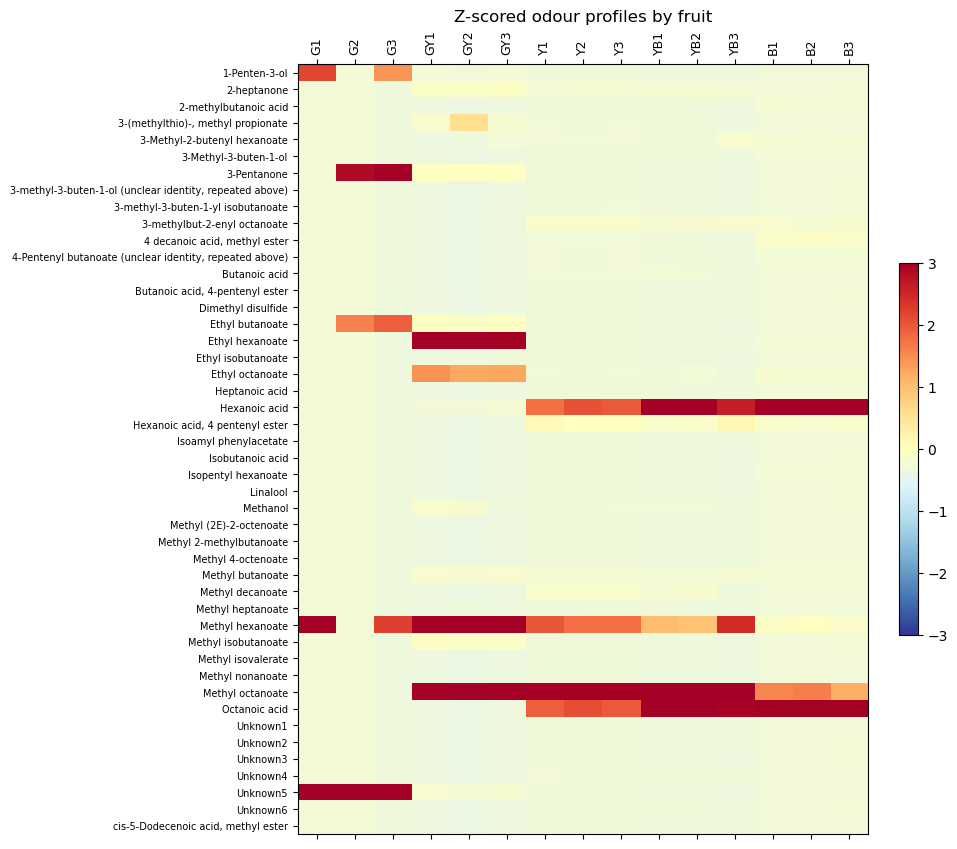

In [4]:
# Heatmap of the z-scored odour profiles, fruits ordered by ripeness stage
figure(figsize=(8, 10))
im = matshow(tidy[odour_cols].values.T, fignum=0, cmap='RdYlBu_r', aspect='auto', vmin=-3, vmax=3)
gca().axis('auto')
yticks(range(len(odour_cols)), odour_cols, fontsize=7)
xticks(range(len(tidy)), tidy['Sample'], rotation=90, fontsize=9)
colorbar(im, fraction=0.03)
title('Z-scored odour profiles by fruit');

## Step 1: L1 logistic regression — accuracy and number of odours used

`Analysis` fits all models with leave-one-fruit-out cross-validation. We first fit with a provisional $K$, read off the sparsity of the L1 model, and refit with $K$ set to the mean number of odours it used.

In [5]:
reload(ripeness)
A = ripeness.Analysis(k=6, seed=2)
results = A.fit_models()
A.compute_sparsity()
print("Odours used per fold:", A.sparsity)
k_hat = int(round(np.mean(A.sparsity)))
print(f"Mean sparsity: {np.mean(A.sparsity):.2f} -> K = {k_hat}")

/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


Odours used per fold: [5, 5, 5, 6, 5, 5, 5, 5, 5, 5, 5, 4, 6, 4, 5]
Mean sparsity: 5.00 -> K = 5


In [6]:
# Refit with K set from the L1 sparsity, if different
if k_hat != A.k:
    A = ripeness.Analysis(k=k_hat, seed=2)
    results = A.fit_models()
    A.compute_sparsity()
print(f"K = {A.k}")
print(f"LogReg_L1 mean accuracy: {np.mean(results['logreg_l1']['test_score']):.2f}")

/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


/opt/anaconda3/envs/numpyro-env/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


K = 5
LogReg_L1 mean accuracy: 0.93


## Steps 2 & 3: selector accuracies and the random-$K$-odour null

In [7]:
A.compute_pc_var_overlap()
A.compute_confusion_matrices()
A.compute_p_values(n_rand=1000)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 2/1000 [00:00<00:58, 16.93it/s]

  0%|          | 4/1000 [00:00<00:56, 17.65it/s]

  1%|          | 6/1000 [00:00<00:55, 17.98it/s]

  1%|          | 8/1000 [00:00<00:57, 17.18it/s]

  1%|          | 10/1000 [00:00<00:59, 16.69it/s]

... (492 outputs left out)

100%|█████████▉| 996/1000 [00:55<00:00, 18.27it/s]

100%|█████████▉| 998/1000 [00:55<00:00, 16.57it/s]

100%|██████████| 1000/1000 [00:56<00:00, 17.04it/s]

100%|██████████| 1000/1000 [00:56<00:00, 17.86it/s]

In [8]:
for name in A.models:
    print(f"{name:10s} mean accuracy = {A.model_scores_agg[name]:.2f}   p = {A.p_values_agg[name]:.3f}")

logreg_l1  mean accuracy = 0.93   p = 0.001
pc_k       mean accuracy = 0.93   p = 0.001
var_k      mean accuracy = 0.93   p = 0.001
corr_k     mean accuracy = 0.93   p = 0.001
dummy      mean accuracy = 0.20   p = 0.341


## Results figure

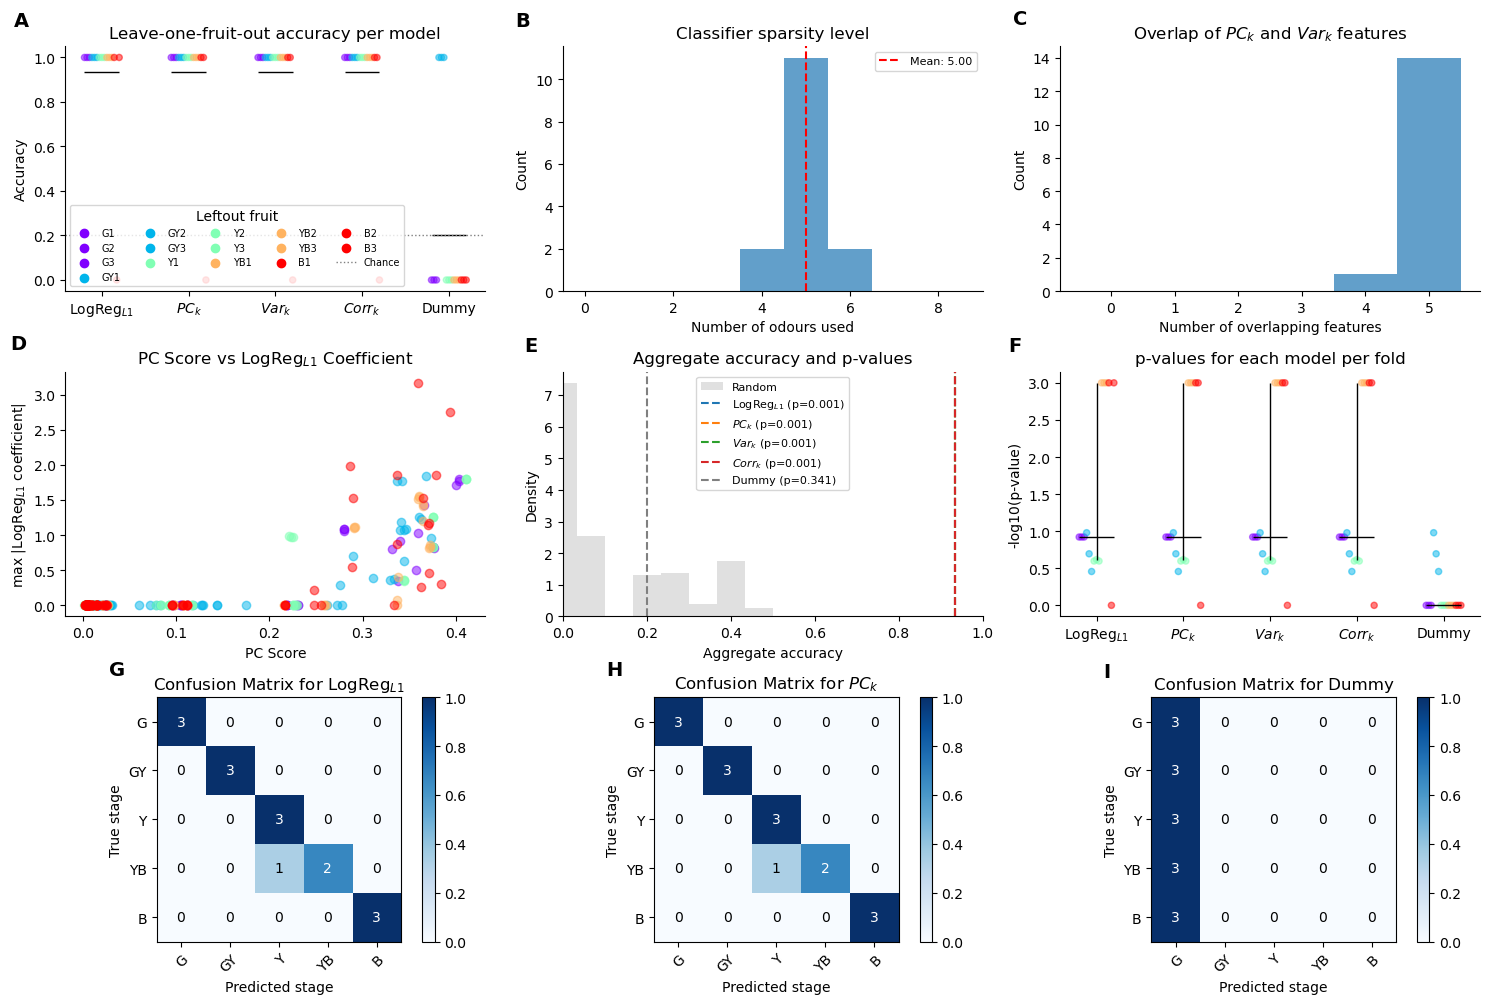

In [9]:
reload(common)
pr = ripeness.PlotResults(A, colorby="ripeness")
pr.plot_figure()
plt.savefig(os.path.join(paths.figs_path, "ripeness_all.pdf"), bbox_inches=None)

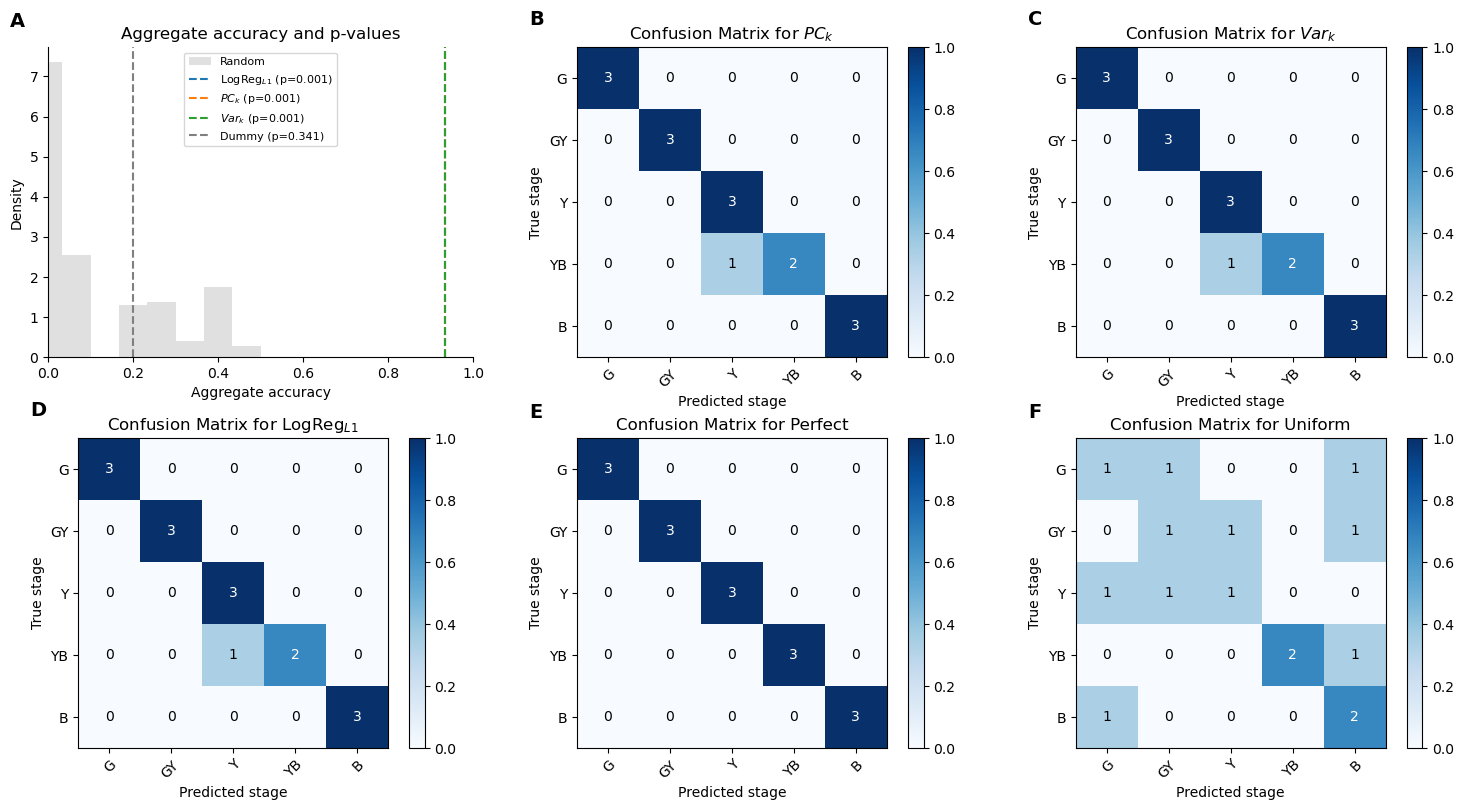

In [10]:
# Compact figure for the paper
pr.plot_figure(panels=[
    (0, 0, "A", pr.plot_aggregate_p_values, ["logreg_l1", "pc_k", "var_k", "dummy"]),
    (0, 1, "B", pr.plot_confusion_matrix, "pc_k"),
    (0, 2, "C", pr.plot_confusion_matrix, "var_k"),
    (1, 0, "D", pr.plot_confusion_matrix, "logreg_l1"),
    (1, 1, "E", pr.plot_confusion_matrix, "perfect"),
    (1, 2, "F", pr.plot_confusion_matrix, "uniform"),
], shape=(2, 3), figsize=(15, 8))
plt.savefig(os.path.join(paths.figs_path, "ripeness.pdf"), bbox_inches=None)